<a href="https://colab.research.google.com/github/chahitchhajlani2007/Smart-City-Traffic-Flow-Simulator/blob/main/Smart_City_Traffic_Flow_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
print('NumPy version:', np.__version__)

NumPy version: 2.1.3


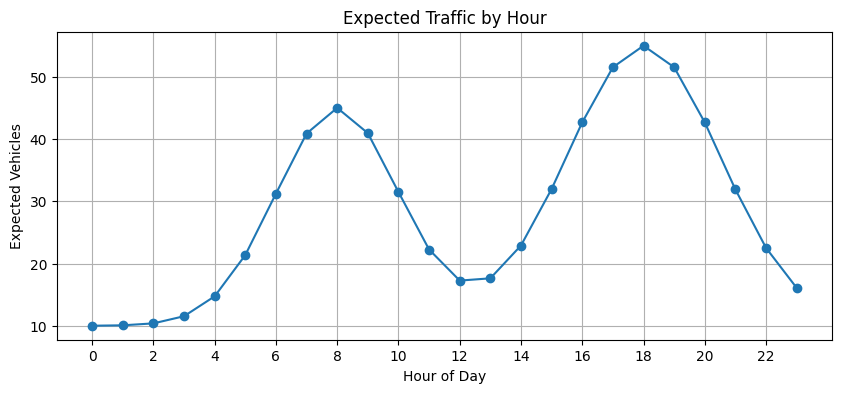

In [ ]:
days = 30
junctions = 10
hours = 24

hour = np.arange(hours)
# Base traffic plus morning and evening rush-hour peaks
morning_peak = 35 * np.exp(-0.5 * ((hour - 8) / 2) ** 2)
evening_peak = 45 * np.exp(-0.5 * ((hour - 18) / 2.5) ** 2)
hourly_curve = 10 + morning_peak + evening_peak

plt.figure(figsize=(10, 4))
plt.plot(hour, hourly_curve, marker='o')
plt.title('Expected Traffic by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Expected Vehicles')
plt.xticks(np.arange(0, 24, 2))
plt.grid(True)
plt.show()

In [ ]:
# Shape: (days, junctions, hours)
# Give each junction a slightly different traffic level
junction_factor = np.linspace(0.8, 1.3, junctions)
traffic_rate = hourly_curve[None, None, :] * junction_factor[None, :, None]
traffic = np.random.poisson(lam=traffic_rate, size=(days, junctions, hours))

print('Traffic array shape:', traffic.shape)
print('Dimensions:', traffic.ndim)
print('Total values:', traffic.size)
print('Data type:', traffic.dtype)
print('Total simulated junction-hour records:', traffic.size)

Traffic array shape: (30, 10, 24)
Dimensions: 3
Total values: 7200
Data type: int64
Total simulated junction-hour records: 7200


In [ ]:
print('Minimum vehicles in one hour:', traffic.min())
print('Maximum vehicles in one hour:', traffic.max())
print('Average vehicles per junction-hour:', round(traffic.mean(), 2))
print('Total vehicles across all simulated records:', traffic.sum())

daily_total = traffic.sum(axis=(1, 2))
junction_total = traffic.sum(axis=(0, 2))
hourly_total = traffic.sum(axis=(0, 1))

print('Busiest day:', np.argmax(daily_total) + 1)
print('Busiest junction:', np.argmax(junction_total) + 1)
print('Busiest hour:', np.argmax(hourly_total), ':00')

Minimum vehicles in one hour: 1
Maximum vehicles in one hour: 92
Average vehicles per junction-hour: 30.3
Total vehicles across all simulated records: 218124
Busiest day: 25
Busiest junction: 10
Busiest hour: 18 :00


In [ ]:
average_by_hour = traffic.mean(axis=(0, 1))
peak_hours = np.argsort(average_by_hour)[-3:][::-1]

print('Top 3 busiest hours across the simulation:')
for h in peak_hours:
    print(f'{h}:00 - average {average_by_hour[h]:.2f} vehicles per junction')

average_by_junction = traffic.mean(axis=(0, 2))
busiest_junction = np.argmax(average_by_junction)
print('\nBusiest junction: Junction', busiest_junction + 1)
print('Average vehicles per hour:', round(average_by_junction[busiest_junction], 2))

Top 3 busiest hours across the simulation:
18:00 - average 58.36 vehicles per junction
17:00 - average 54.20 vehicles per junction
19:00 - average 53.34 vehicles per junction

Busiest junction: Junction 10
Average vehicles per hour: 37.64


In [ ]:
high_traffic_threshold = np.percentile(traffic, 90)
high_traffic_records = traffic[traffic >= high_traffic_threshold]

print('90th percentile traffic threshold:', high_traffic_threshold)
print('Number of high-traffic records:', high_traffic_records.size)
print('Percentage of records at or above threshold:',
      round(high_traffic_records.size / traffic.size * 100, 2), '%')

90th percentile traffic threshold: 55.0
Number of high-traffic records: 723
Percentage of records at or above threshold: 10.04 %


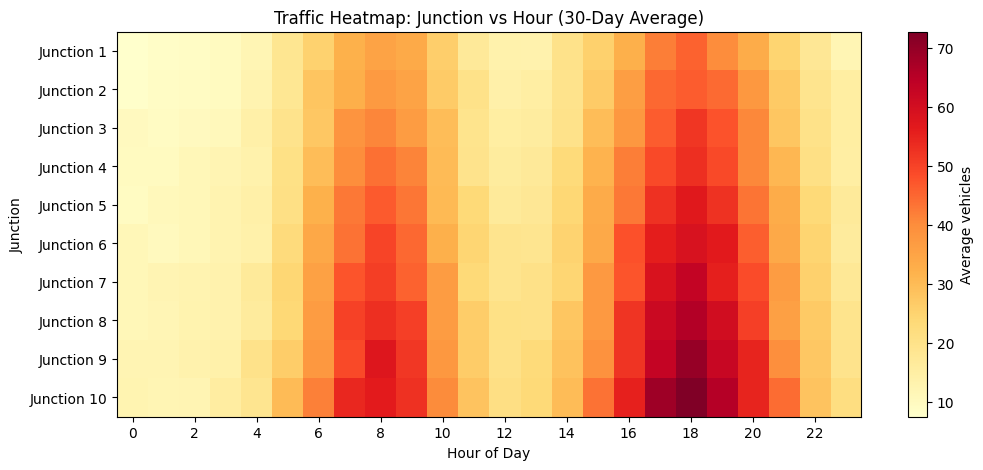

In [ ]:
# Average traffic for each junction and hour across all 30 days
junction_hour_average = traffic.mean(axis=0).mean(axis=0)
# Average across days, giving shape (junctions, hours)
junction_hour_average = traffic.mean(axis=0)

plt.figure(figsize=(12, 5))
plt.imshow(junction_hour_average, aspect='auto', cmap='YlOrRd')
plt.colorbar(label='Average vehicles')
plt.title('Traffic Heatmap: Junction vs Hour (30-Day Average)')
plt.xlabel('Hour of Day')
plt.ylabel('Junction')
plt.xticks(np.arange(0, 24, 2))
plt.yticks(np.arange(junctions), [f'Junction {i+1}' for i in range(junctions)])
plt.show()

In [ ]:
import time

# Loop-based sum
start = time.perf_counter()
loop_total = 0
for d in range(days):
    for j in range(junctions):
        for h in range(hours):
            loop_total += int(traffic[d, j, h])
loop_time = time.perf_counter() - start

# Vectorized NumPy sum
start = time.perf_counter()
numpy_total = traffic.sum()
numpy_time = time.perf_counter() - start

print('Loop total:', loop_total)
print('NumPy total:', numpy_total)
print('Totals match:', loop_total == numpy_total)
print(f'Loop time: {loop_time:.6f} seconds')
print(f'NumPy time: {numpy_time:.6f} seconds')

Loop total: 218124
NumPy total: 218124
Totals match: True
Loop time: 0.006400 seconds
NumPy time: 0.000196 seconds
